# Phone Market Analysis
Data: phones scraped from mobiledokan.com on 29 July 2025 (`phones_data_20250729_181901.csv`).

**What I do in this notebook**
1. Load and check the data
2. Clean it (text to numbers, Taka to Rupees)
3. Explore the market (brands, prices, yearly trends)
4. Find which features raise the price
5. Build models to predict price
6. Find bargain phones and guess prices for upcoming phones
7. Group phones into segments

## 1. Import libraries and settings

In [3]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# settings I can change
FILE_NAME = "data/phones_data_20250729_181901.csv"
TAKA_TO_RUPEE = 0.71      # 1 Taka = 0.71 Rupees (approx)
FIRST_YEAR = 2019         # I only study phones from this year

## 2. Load the data

In [4]:
raw = pd.read_csv(FILE_NAME, dtype=str)    # read everything as text first
print("Rows and columns:", raw.shape)
raw.head(3)

Rows and columns: (4144, 86)


,brand,model,device_type,release_date,status,architecture,aspect_ratio,audio_jack,battery_capacity,battery_placement,battery_type,bezel_less_display,bluetooth,brightness,chipset,colors,cpu,cpu_cores,detail_url,display_type,...,selfie_camera_resolution,selfie_camera_setup,sensors,sim_size,sim_slot,speed,storage_type,thickness,touch_screen,usb,usb_otg,usb_type_c,user_interface,video,volte,waterproof,weight,width,wifi_hotspot,wlan
0,Oppo,K13 Turbo Pro (512GB),Smartphone,25 July 2025,Available,64 bit,19.5:9,USB Type-C,Li-Po 7000mAh,NaN,NaN,NaN,v5.4,1600 nits,Qualcomm SM8735 Snapdragon 8s Gen 4,"Black Warrior, Purple No. 1, Knight Silver",Octa-core (1x3.21 GHz Cortex-X4 & 3x3.0 GHz Co...,8 Cores,https://www.mobiledokan.com/mobile/oppo-k13-tu...,AMOLED,...,NaN,NaN,NaN,"SIM1: Nano, SIM2: Nano","Dual SIM, GSM+GSM","HSPA, LTE, 5G",UFS 4.0,7.3 mm,"Capacitive Touchscreen, Multi-touch","Mass storage device, USB charging",Yes,USB Type-C 2.0,ColorOS 15,"4K@30/60fps, 1080p@30fps",Yes,Water resistant (up to 2m for 30 min),208 grams,77.2 mm,NaN,"Wi-Fi 7 (802.11 a/b/g/n/ac/be/ax) 5GHz 6GHz, MIMO"
1,Oppo,K13 Turbo (512GB),Smartphone,25 July 2025,Available,64 bit,19.5:9,USB Type-C,Li-Po 7000mAh,NaN,NaN,NaN,v5.4,1600 nits,Mediatek Dimensity 8450,"Black Warrior, Purple No. 1, Knight White",Octa-core (1x3.25 GHz Cortex-A725 & 3x3.0 GHz ...,8 Cores,https://www.mobiledokan.com/mobile/oppo-k13-tu...,AMOLED,...,NaN,NaN,NaN,"SIM1: Nano, SIM2: Nano","Dual SIM, GSM+GSM","HSPA, LTE, 5G",UFS 3.1,7.3 mm,"Capacitive Touchscreen, Multi-touch","Mass storage device, USB charging",Yes,USB Type-C 2.0,ColorOS 15,"4K@30/60fps, 1080p@30fps",Yes,Water resistant (up to 2m for 30 min),207 grams,77.2 mm,NaN,"Wi-Fi 6 (802.11 a/b/g/n/ac/ax) 5GHz, MIMO"
2,Vivo,Y400,Smartphone,Not announced yet,Rumored,64 bit,NaN,USB Type-C,Li-Po 6000mAh,NaN,NaN,NaN,v5.0,NaN,Qualcomm SM6225 Snapdragon 685,Green; other colors,Octa-core (2x2.2 GHz Cortex-A78 & 6x1.95 GHz C...,8 Cores,https://www.mobiledokan.com/mobile/vivo-y400,AMOLED,...,NaN,NaN,NaN,"SIM1: Nano, SIM2: Nano","Dual SIM, GSM+GSM","HSPA, LTE",NaN,NaN,"Capacitive Touchscreen, Multi-touch","Mass storage device, USB charging",Yes,USB Type-C 2.0,Funtouch 15,"1080p@30fps, gyro-EIS",Yes,Water resistant (up to 1.5m for 30 min),NaN,NaN,NaN,Wi-Fi 5 (802.11 a/b/g/n/ac) 5GHz


## 3. First look: missing values

In [5]:
missing_percent = (raw.isna().mean() * 100).sort_values(ascending=False)

empty_columns = list(missing_percent[missing_percent == 100].index)
print("Columns that are 100% empty:", empty_columns)

print("\nMost missing columns that still have some data (%):")
missing_percent[missing_percent < 100].head(10).round(0)

Columns that are 100% empty: ['made_by', 'battery_placement', 'primary_camera_autofocus', 'primary_camera_features', 'primary_camera_flash', 'sensors', 'primary_camera_image_resolution', 'bezel_less_display', 'selfie_camera_resolution', 'battery_type', 'primary_camera_settings', 'primary_camera_setup', 'primary_camera_shooting_modes', 'primary_camera_video_fps', 'primary_camera_video_recording', 'primary_camera_zoom', 'wifi_hotspot', 'selfie_camera_setup']

Most missing columns that still have some data (%):


price_savings       95.0
price_old           95.0
ruggedness          68.0
ip_rating           67.0
waterproof          63.0
price_unofficial    62.0
brightness          56.0
user_interface      46.0
storage_type        42.0
ram_type            41.0
dtype: float64

## 4. Helper functions
The data stores numbers as text (like `256GB` or `17,999`), so I write small functions to turn them into numbers.

In [6]:
def first_number(column):
    # '6.7 inch' -> 6.7
    return pd.to_numeric(column.str.extract(r"([\d.]+)")[0], errors="coerce")


def to_gb(column):
    # '512MB' -> 0.5 , '8GB' -> 8 , '1TB' -> 1024
    number = first_number(column)
    number = number.where(~column.str.contains("MB", na=False), number / 1024)
    number = number.where(~column.str.contains("TB", na=False), number * 1024)
    return number


def biggest_watt(text):
    # '80W wired, 13.5W PD' -> 80
    if not isinstance(text, str):
        return np.nan
    watts = re.findall(r"(\d+(?:\.\d+)?)\s*W", text)
    return max(float(w) for w in watts) if watts else np.nan


def chipset_maker(text):
    if not isinstance(text, str):
        return np.nan
    text = text.lower()
    if re.search(r"qualcomm|snapdragon", text):
        return "Qualcomm"
    if re.search(r"mediatek|dimensity|helio|mtk", text):
        return "MediaTek"
    if "apple" in text:
        return "Apple"
    if "exynos" in text:
        return "Samsung Exynos"
    if re.search(r"unisoc|spreadtrum|tiger", text):
        return "Unisoc"
    if re.search(r"kirin|hisilicon", text):
        return "HiSilicon Kirin"
    if "tensor" in text:
        return "Google Tensor"
    return "Other"


def taka_to_rupee(column):
    # '23,999' -> 23999 Taka -> Rupees
    taka = pd.to_numeric(column.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
    return taka * TAKA_TO_RUPEE

## 5. Clean the data

In [7]:
phones = raw.drop(columns=empty_columns).copy()

# junk rows from scraping
phones = phones[phones["brand"] != "Comparisons"].reset_index(drop=True)
phones["status"] = phones["status"].where(phones["status"] != "Status")

# same brand written in different ways -> keep the most common spelling
brand_lower = phones["brand"].str.strip().str.lower()
common_spelling = phones.groupby(brand_lower)["brand"].agg(lambda x: x.value_counts().index[0])
phones["brand"] = brand_lower.map(common_spelling)

# device type
type_map = {"smartphone": "Smartphone", "featurephone": "Feature phone",
            "javaphone": "Java phone", "symbian": "Symbian"}
phones["device_type_clean"] = phones["device_type"].str.lower().str.replace(" ", "").map(type_map)
is_android_or_ios = phones["operating_system"].fillna("").str.contains("Android|iOS")
phones.loc[phones["device_type_clean"].isna() & is_android_or_ios, "device_type_clean"] = "Smartphone"
phones["is_smartphone"] = phones["device_type_clean"] == "Smartphone"

# release year
release_text = phones["release_date"].str.replace(r"^Exp\.\s*", "", regex=True)
year = pd.to_numeric(release_text.str.extract(r"\b((?:19|20)\d{2})\b")[0], errors="coerce")
phones["release_year"] = year.where(year <= 2026)

# prices (Taka -> Rupees)
phones["official_price"] = taka_to_rupee(phones["price_official"])
phones["unofficial_price"] = taka_to_rupee(phones["price_unofficial"])
phones["price_inr"] = phones["official_price"].fillna(phones["unofficial_price"])
phones["price_type"] = "none"
phones.loc[phones["unofficial_price"].notna(), "price_type"] = "unofficial"
phones.loc[phones["official_price"].notna(), "price_type"] = "official"

# how old is the price?
scrape_date = pd.to_datetime(phones["scraped_at"]).max().normalize()
price_date = pd.to_datetime(phones["price_updated"], format="%B %d, %Y", errors="coerce")
phones["days_since_price_update"] = (scrape_date - price_date).dt.days

# specs as numbers
phones["ram_gb"] = to_gb(phones["ram"])
phones["storage_gb"] = to_gb(phones["internal_storage"])
phones["battery_mah"] = pd.to_numeric(phones["battery_capacity"].str.extract(r"(\d{3,6})\s*mAh")[0], errors="coerce")
phones["screen_inches"] = pd.to_numeric(phones["screen_size"].str.extract(r"^\s*([\d.]+)")[0], errors="coerce")
phones["refresh_rate_hz"] = first_number(phones["refresh_rate"])
phones["charging_watts"] = phones["quick_charging"].map(biggest_watt)
phones["main_camera_mp"] = first_number(phones["primary_camera_resolution"])
phones["rear_cameras"] = phones["primary_camera_resolution"].map(
    lambda t: len(re.findall(r"\d+(?:\.\d+)?", t)) if isinstance(t, str) else np.nan)
phones["process_nm"] = first_number(phones["fabrication"])
phones["weight_grams"] = first_number(phones["weight"].where(phones["weight"].str.contains("g", na=False)))
phones["wifi_generation"] = pd.to_numeric(phones["wlan"].str.extract(r"Wi-?Fi\s*([4-7])")[0], errors="coerce")
phones["android_version"] = pd.to_numeric(phones["operating_system"].str.extract(r"Android v?(\d+)")[0], errors="coerce")
phones["chipset_maker"] = phones["chipset"].map(chipset_maker)

# yes / no features
phones["has_5g"] = (phones["network"].fillna("") + phones["speed"].fillna("")).str.contains("5G")
phones["has_oled"] = phones["display_type"].fillna("").str.contains("OLED")
phones["has_wireless_charging"] = phones["quick_charging"].fillna("").str.contains("wireless", case=False)
phones["has_ip_rating"] = phones["ip_rating"].notna()
phones["has_headphone_jack"] = phones["audio_jack"].fillna("").str.contains(r"3\.5")
phones["has_sd_slot"] = phones["expandable_memory"].notna() & (phones["expandable_memory"].fillna("").str.lower() != "no")
phones["has_usb_c"] = phones["usb_type_c"].notna() | phones["usb"].fillna("").str.contains("Type-C", case=False)
phones["is_ufs_storage"] = phones["storage_type"].fillna("").str.contains("UFS")

# remove values that are impossible (scraping mistakes)
allowed = {"ram_gb": (0.06, 64), "storage_gb": (0.004, 4096), "battery_mah": (300, 30000),
           "screen_inches": (1, 10), "refresh_rate_hz": (30, 500), "weight_grams": (30, 1500),
           "main_camera_mp": (0.1, 250), "price_inr": (200, 800000)}
for column, (low, high) in allowed.items():
    phones.loc[~phones[column].between(low, high), column] = np.nan

smartphones = phones[phones["is_smartphone"]].copy()
print("All rows:", len(phones), "| smartphones:", len(smartphones),
      "| smartphones with a price:", smartphones["price_inr"].notna().sum())
phones[["brand", "model", "release_year", "price_inr", "price_type", "ram_gb", "storage_gb", "battery_mah"]].head()

All rows: 4142 | smartphones: 4111 | smartphones with a price: 3740


,brand,model,release_year,price_inr,price_type,ram_gb,storage_gb,battery_mah
0,Oppo,K13 Turbo Pro (512GB),2025.0,39760.00,unofficial,12.0,512.0,7000.0
1,Oppo,K13 Turbo (512GB),2025.0,36920.00,unofficial,12.0,512.0,7000.0
2,Vivo,Y400,NaN,NaN,none,8.0,128.0,6000.0
3,Infinix,Hot 60 Pro Plus (256GB),2025.0,17039.29,official,8.0,256.0,5160.0
4,Realme,Note 70T,2025.0,NaN,none,4.0,128.0,6000.0


## 6. Quick quality checks

In [8]:
checks = pd.Series({
    "Same brand + model appears more than once": int(phones.duplicated(["brand", "model"], keep=False).sum()),
    "Status is 'Upcoming' but release year is in the past": int(((phones["status"] == "Upcoming") & (phones["release_year"] < 2025)).sum()),
    "Price is older than 1 year": int((phones["days_since_price_update"] > 365).sum()),
    "Phones with no price": int(phones["price_inr"].isna().sum()),
})
checks

Same brand + model appears more than once               118
Status is 'Upcoming' but release year is in the past    178
Price is older than 1 year                              497
Phones with no price                                    371
dtype: int64

## 7. Market overview

Number of brands: 66
Top 5 brands hold 42 % of phones
Top 10 brands hold 62 % of phones

Price summary in Rupees:
count      3740.0
mean      24612.0
std       30074.0
min        1065.0
25%        7809.0
50%       14199.0
75%       28754.0
max      482800.0


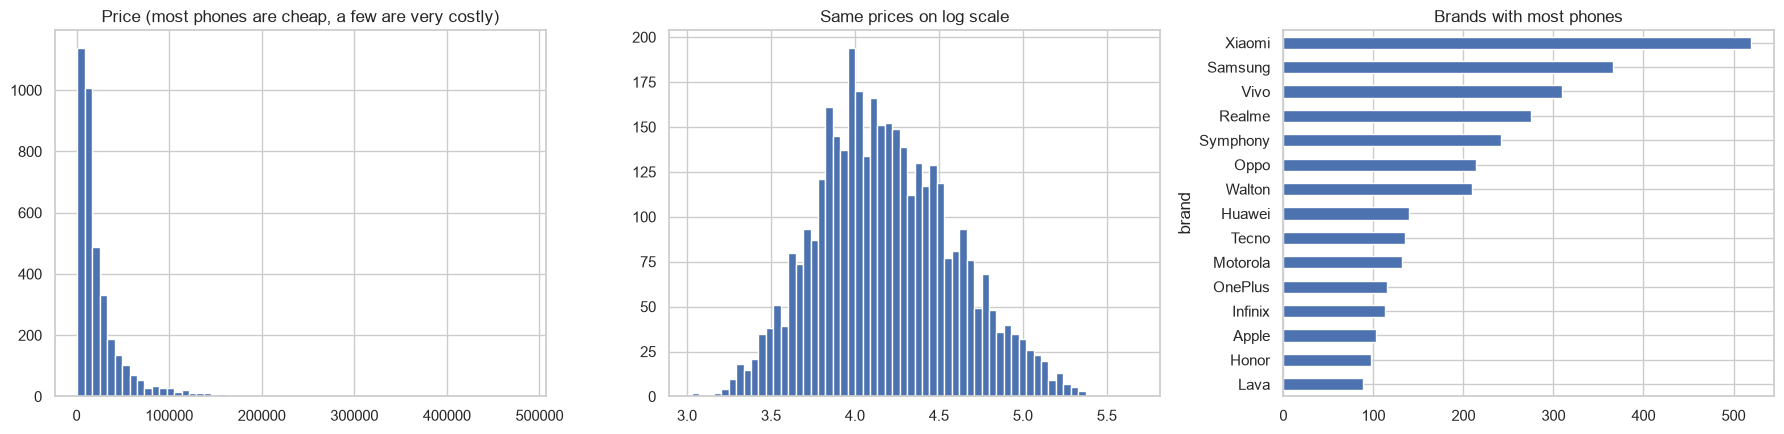

In [9]:
brand_counts = smartphones["brand"].value_counts()
print("Number of brands:", len(brand_counts))
print("Top 5 brands hold", round(brand_counts.head(5).sum() / brand_counts.sum() * 100), "% of phones")
print("Top 10 brands hold", round(brand_counts.head(10).sum() / brand_counts.sum() * 100), "% of phones")
print()
print("Price summary in Rupees:")
print(smartphones["price_inr"].describe().round(0).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(smartphones["price_inr"].dropna(), bins=60)
axes[0].set_title("Price (most phones are cheap, a few are very costly)")
axes[1].hist(np.log10(smartphones["price_inr"].dropna()), bins=60)
axes[1].set_title("Same prices on log scale")
brand_counts.head(15)[::-1].plot.barh(ax=axes[2])
axes[2].set_title("Brands with most phones")
plt.tight_layout()
plt.show()

In [10]:
band_edges = [0, 5000, 10000, 20000, 40000, 70000, np.inf]
band_names = ["under 5k", "5k-10k", "10k-20k", "20k-40k", "40k-70k", "above 70k"]
smartphones["price_band"] = pd.cut(smartphones["price_inr"], band_edges, labels=band_names)

print("Share of priced smartphones in each price band (%):")
(smartphones["price_band"].value_counts(normalize=True).reindex(band_names) * 100).round(1)

Share of priced smartphones in each price band (%):


price_band
under 5k     11.7
5k-10k       23.8
10k-20k      27.9
20k-40k      20.3
40k-70k       9.6
above 70k     6.7
Name: proportion, dtype: float64

## 8. Yearly trends
From here I only use smartphones released in or after `FIRST_YEAR` that have a price.

Phones used: 2478


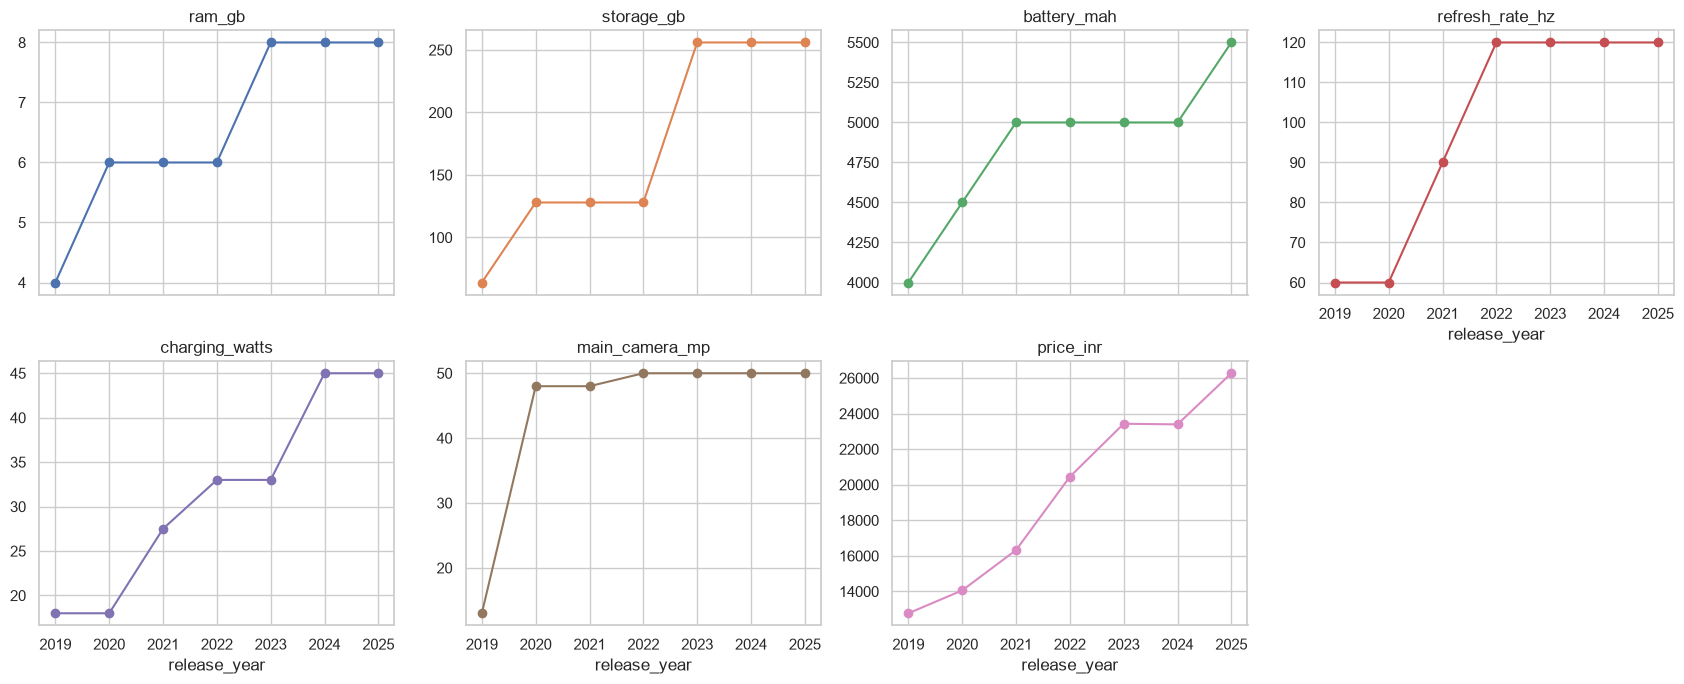

,ram_gb,storage_gb,battery_mah,refresh_rate_hz,charging_watts,main_camera_mp,price_inr
release_year,,,,,,,
2019.0,4.0,64.0,4000.0,60.0,18.0,13.0,12772.9
2020.0,6.0,128.0,4500.0,60.0,18.0,48.0,14058.0
2021.0,6.0,128.0,5000.0,90.0,27.5,48.0,16322.9
2022.0,6.0,128.0,5000.0,120.0,33.0,50.0,20448.0
2023.0,8.0,256.0,5000.0,120.0,33.0,50.0,23429.6
2024.0,8.0,256.0,5000.0,120.0,45.0,50.0,23393.8
2025.0,8.0,256.0,5500.0,120.0,45.0,50.0,26270.0


In [11]:
modern = smartphones[(smartphones["release_year"] >= FIRST_YEAR) & smartphones["price_inr"].notna()].reset_index(drop=True)
print("Phones used:", len(modern))

trend_columns = ["ram_gb", "storage_gb", "battery_mah", "refresh_rate_hz", "charging_watts", "main_camera_mp", "price_inr"]
median_by_year = modern.groupby("release_year")[trend_columns].median()
median_by_year.plot(subplots=True, layout=(2, 4), figsize=(17, 7), marker="o", legend=False, title=trend_columns)
plt.tight_layout()
plt.show()
median_by_year.round(1)

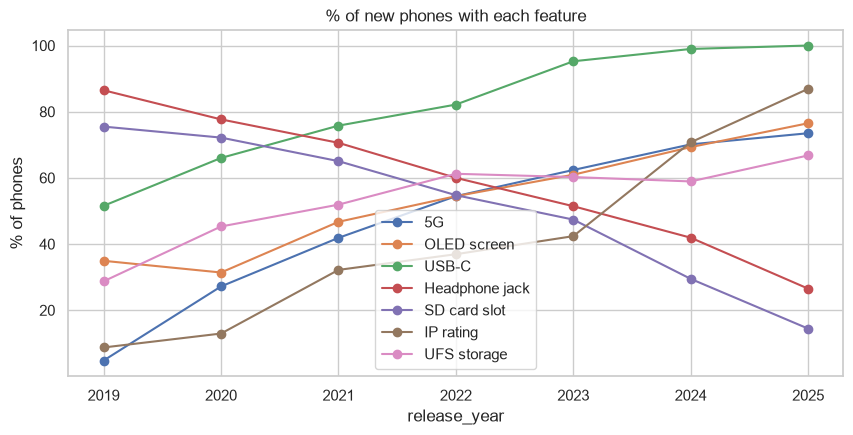

In [12]:
features = {"5G": "has_5g", "OLED screen": "has_oled", "USB-C": "has_usb_c", "Headphone jack": "has_headphone_jack",
            "SD card slot": "has_sd_slot", "IP rating": "has_ip_rating", "UFS storage": "is_ufs_storage"}
adoption = pd.DataFrame({name: modern.groupby("release_year")[col].mean() * 100 for name, col in features.items()})

adoption.plot(marker="o", figsize=(10, 4.5), title="% of new phones with each feature")
plt.ylabel("% of phones")
plt.show()

## 9. Price analysis

In [13]:
# official vs unofficial (grey market) price
both = phones.dropna(subset=["official_price", "unofficial_price"])
ratio = both["unofficial_price"] / both["official_price"]
print("Phones with both prices:", len(both))
print(f"Typical unofficial price = {ratio.median():.2f} x official price")
print(f"Unofficial is cheaper for {(ratio < 1).mean() * 100:.0f}% of these phones")

Phones with both prices: 306
Typical unofficial price = 0.78 x official price
Unofficial is cheaper for 97% of these phones


,phones,median_price
brand,,
Symphony,87,5679.0
Itel,63,6170.0
Walton,88,7490.0
Nokia,34,8875.0
Tecno,100,9940.0
Infinix,98,10646.0
Realme,248,17218.0
Xiaomi,436,19170.0
Motorola,102,19880.0


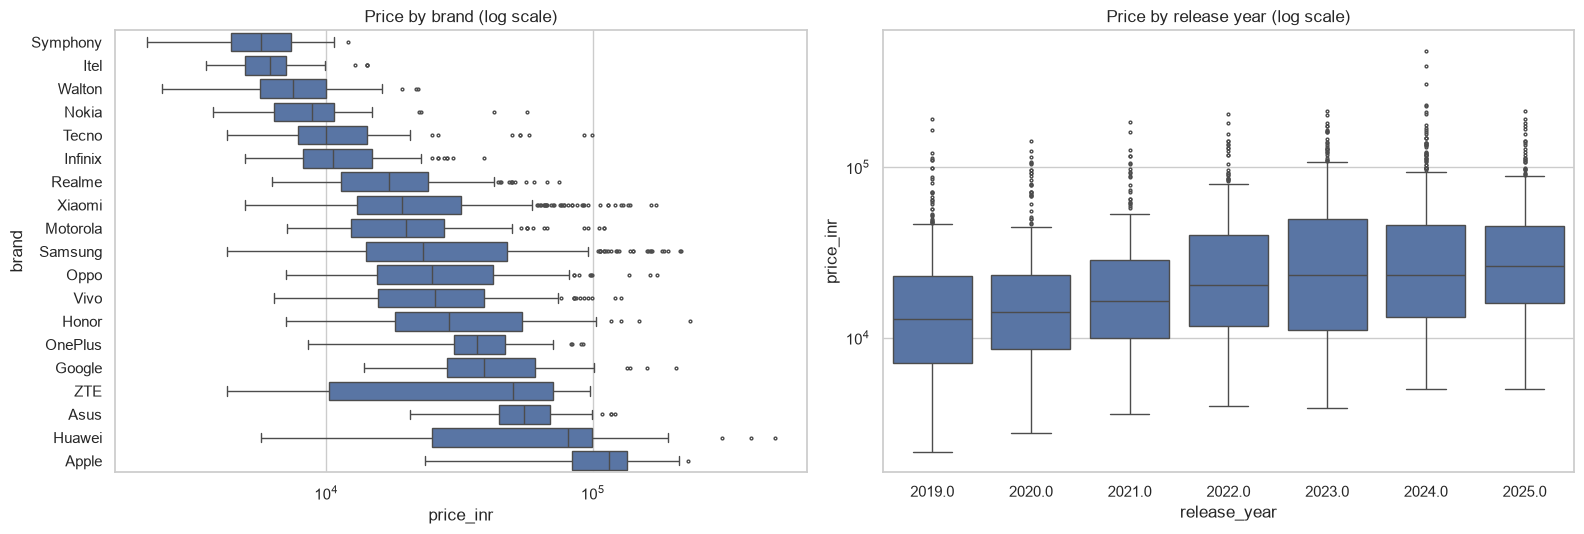

In [14]:
# price by brand (only brands with 25+ phones)
big_brands = modern["brand"].value_counts().loc[lambda c: c >= 25].index
brand_table = (modern[modern["brand"].isin(big_brands)].groupby("brand")["price_inr"]
               .agg(phones="count", median_price="median").sort_values("median_price"))
display(brand_table.round(0))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.boxplot(data=modern[modern["brand"].isin(big_brands)], y="brand", x="price_inr",
            order=brand_table.index, ax=axes[0], fliersize=2)
axes[0].set_xscale("log")
axes[0].set_title("Price by brand (log scale)")
sns.boxplot(data=modern, x="release_year", y="price_inr", ax=axes[1], fliersize=2)
axes[1].set_yscale("log")
axes[1].set_title("Price by release year (log scale)")
plt.tight_layout()
plt.show()

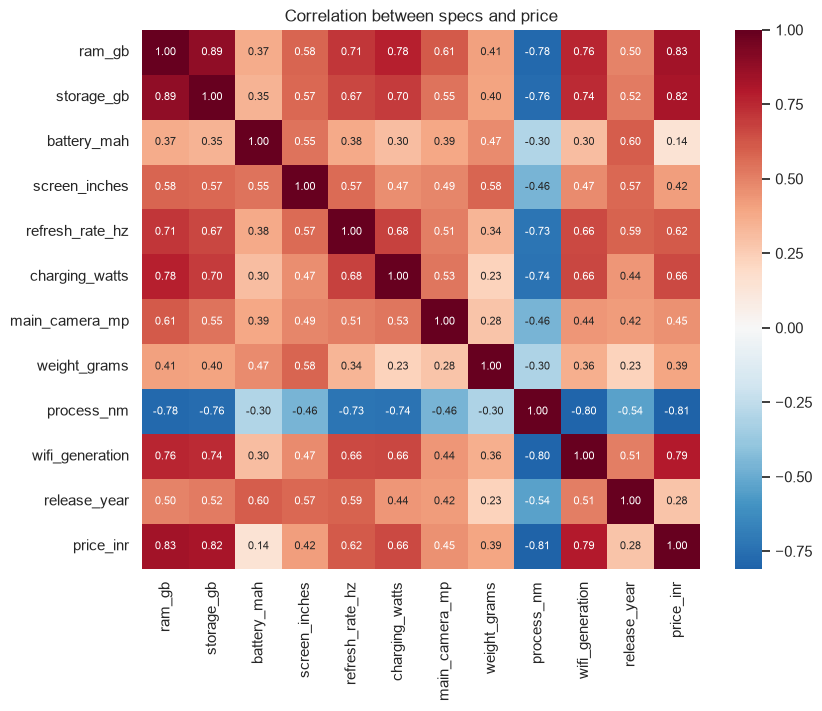

In [15]:
corr_columns = ["ram_gb", "storage_gb", "battery_mah", "screen_inches", "refresh_rate_hz", "charging_watts",
                "main_camera_mp", "weight_grams", "process_nm", "wifi_generation", "release_year", "price_inr"]
plt.figure(figsize=(9, 7))
sns.heatmap(modern[corr_columns].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 8})
plt.title("Correlation between specs and price")
plt.show()

## 10. Which features raise the price?
To compare fairly, I use a simple regression on the **log of price**. It keeps RAM, storage, battery, screen, year and brand the same,
and then checks how much extra price a feature adds.
The numbers are rough estimates, not exact facts.

Note: *Headphone jack* and *SD card slot* show negative numbers because they mark older or budget designs, not because they make a phone cheaper.

,feature,phones_with_feature,extra_price_%
0,Name has 'Ultra',79,64.5
1,OLED screen,1351,56.1
2,5G,1218,53.2
3,Refresh rate 120 Hz or more,1178,47.4
4,Charging 65 W or more,680,47.0
5,UFS storage,1327,36.8
6,IP water/dust rating,1062,22.9
7,Name has 'Pro',507,12.4
8,Name has 'Lite',50,-12.3
9,SD card slot,1241,-26.6


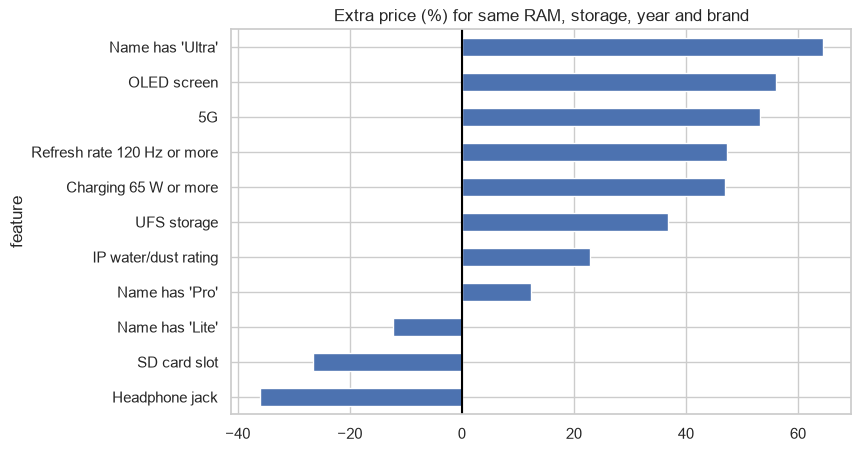

In [16]:
modern["log_price"] = np.log(modern["price_inr"])

# things to keep equal
base = pd.DataFrame({
    "log2_ram": np.log2(modern["ram_gb"]),
    "log2_storage": np.log2(modern["storage_gb"]),
    "battery_thousand": modern["battery_mah"] / 1000,
    "screen_inches": modern["screen_inches"],
})
base = base.fillna(base.median())
year_columns = pd.get_dummies(modern["release_year"].astype(int), prefix="year", drop_first=True, dtype=float)
small_brands = modern["brand"].map(modern["brand"].value_counts()) < 15
brand_columns = pd.get_dummies(modern["brand"].mask(small_brands, "Other"), prefix="brand", drop_first=True, dtype=float)
controls = pd.concat([base, year_columns, brand_columns], axis=1)

# features to test
tests = {
    "5G": modern["has_5g"],
    "OLED screen": modern["has_oled"],
    "Refresh rate 120 Hz or more": modern["refresh_rate_hz"] >= 120,
    "Charging 65 W or more": modern["charging_watts"] >= 65,
    "Wireless charging": modern["has_wireless_charging"],
    "IP water/dust rating": modern["has_ip_rating"],
    "UFS storage": modern["is_ufs_storage"],
    "Headphone jack": modern["has_headphone_jack"],
    "SD card slot": modern["has_sd_slot"],
    "Name has 'Pro'": modern["model"].str.contains(r"\bPro\b", case=False),
    "Name has 'Ultra'": modern["model"].str.contains(r"\bUltra\b", case=False),
    "Name has 'Lite'": modern["model"].str.contains(r"\bLite\b", case=False),
}

rows = []
for name, flag in tests.items():
    flag = flag.fillna(False).astype(float)
    if flag.sum() < 15:
        continue
    X = controls.copy()
    X["feature"] = flag
    model = LinearRegression().fit(X, modern["log_price"])
    extra = (np.exp(model.coef_[list(X.columns).index("feature")]) - 1) * 100
    rows.append({"feature": name, "phones_with_feature": int(flag.sum()), "extra_price_%": round(extra, 1)})

feature_table = pd.DataFrame(rows).sort_values("extra_price_%", ascending=False).reset_index(drop=True)
display(feature_table)

feature_table.iloc[::-1].plot.barh(x="feature", y="extra_price_%", legend=False, figsize=(8, 5),
                                   title="Extra price (%) for same RAM, storage, year and brand")
plt.axvline(0, color="black")
plt.show()

In [17]:
# how much does doubling RAM or storage change the price?
spec_model = LinearRegression().fit(controls, modern["log_price"])
coef = pd.Series(spec_model.coef_, index=controls.columns)
print(f"Doubling RAM     -> price changes by about {(np.exp(coef['log2_ram']) - 1) * 100:+.0f}%")
print(f"Doubling storage -> price changes by about {(np.exp(coef['log2_storage']) - 1) * 100:+.0f}%")

Doubling RAM     -> price changes by about +67%
Doubling storage -> price changes by about +20%


## 11. Predict phone price (machine learning)
- The target is the **log of price**.
- I split by **phone family** (for example all storage versions of one model stay together),
  so the model cannot "cheat" by seeing a near-copy of the same phone in training.

In [18]:
def make_features(table):
    x = pd.DataFrame(index=table.index)
    for column in ["ram_gb", "storage_gb", "battery_mah", "screen_inches", "refresh_rate_hz", "charging_watts",
                   "main_camera_mp", "rear_cameras", "weight_grams", "process_nm", "wifi_generation",
                   "android_version", "release_year"]:
        x[column] = table[column]
    for column in ["has_5g", "has_oled", "has_wireless_charging", "has_ip_rating", "has_headphone_jack",
                   "has_sd_slot", "has_usb_c", "is_ufs_storage"]:
        x[column] = table[column].astype(float)
    makers = pd.get_dummies(table["chipset_maker"], prefix="chipset", dtype=float)
    return pd.concat([x, makers], axis=1)


X = make_features(modern)
y = np.log(modern["price_inr"]).values
family = (modern["brand"] + " | " + modern["model"].str.replace(r"\s*\(.*\)", "", regex=True)).values
print("Features:", X.shape[1], "| phones:", len(X))

Features: 29 | phones: 2478


In [19]:
def new_ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 15)))

def new_forest():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestRegressor(n_estimators=120, min_samples_leaf=2, max_features=0.4, random_state=0))

def new_boosting():
    return HistGradientBoostingRegressor(max_iter=350, learning_rate=0.08, max_leaf_nodes=15,
                                         min_samples_leaf=30, l2_regularization=2, random_state=0)


def predict_with_cv(make_model, splitter, groups=None):
    # every phone is predicted by a model that did not see it in training
    predictions = np.zeros(len(y))
    for train_rows, test_rows in splitter.split(X, y, groups):
        model = make_model().fit(X.iloc[train_rows], y[train_rows])
        predictions[test_rows] = model.predict(X.iloc[test_rows])
    return predictions


def score(actual, predicted):
    percent_error = np.abs(np.exp(predicted) - np.exp(actual)) / np.exp(actual)
    return {"R2": round(r2_score(actual, predicted), 3),
            "typical error %": round(np.median(percent_error) * 100, 1),
            "within 20% of real price (%)": round((percent_error <= 0.2).mean() * 100, 1)}


predictions = {}
scores = {}
for name, maker in [("Ridge (simple)", new_ridge), ("Random forest", new_forest), ("Gradient boosting", new_boosting)]:
    predictions[name] = predict_with_cv(maker, GroupKFold(n_splits=5), family)
    scores[name] = score(y, predictions[name])

# for comparison: a careless split gives a score that is too good
careless = predict_with_cv(new_boosting, KFold(5, shuffle=True, random_state=0))
scores["Gradient boosting - careless split (too optimistic)"] = score(y, careless)

pd.DataFrame(scores).T

,R2,typical error %,within 20% of real price (%)
Ridge (simple),0.890,17.6,55.4
Random forest,0.927,12.5,70.3
Gradient boosting,0.929,12.3,69.9
Gradient boosting - careless split (too optimistic),0.944,10.9,75.0


80% price range = predicted price / 1.30  to  predicted price x 1.30


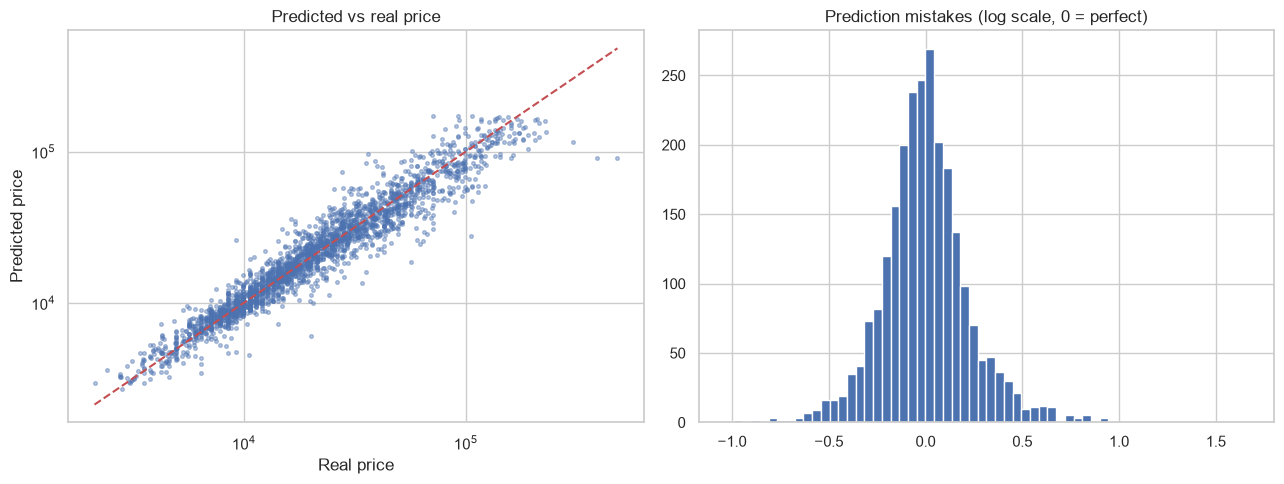

Typical % error in each price band:


band
under 5k     11.8
5k-10k        9.1
10k-20k      10.5
20k-40k      13.9
40k-70k      15.4
above 70k    20.3
Name: error_%, dtype: float64

In [20]:
best = predictions["Gradient boosting"]
mistakes = y - best

# 80% of predictions are inside this range
range_half = np.quantile(np.abs(mistakes), 0.80)
range_factor = np.exp(range_half)
print(f"80% price range = predicted price / {range_factor:.2f}  to  predicted price x {range_factor:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(np.exp(y), np.exp(best), s=7, alpha=0.4)
low, high = np.exp(y).min(), np.exp(y).max()
axes[0].plot([low, high], [low, high], "r--")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Real price")
axes[0].set_ylabel("Predicted price")
axes[0].set_title("Predicted vs real price")
axes[1].hist(mistakes, bins=60)
axes[1].set_title("Prediction mistakes (log scale, 0 = perfect)")
plt.tight_layout()
plt.show()

error_by_band = pd.DataFrame({"band": pd.cut(np.exp(y), band_edges, labels=band_names),
                              "error_%": np.abs(np.exp(best) - np.exp(y)) / np.exp(y) * 100})
print("Typical % error in each price band:")
error_by_band.groupby("band")["error_%"].median().round(1)

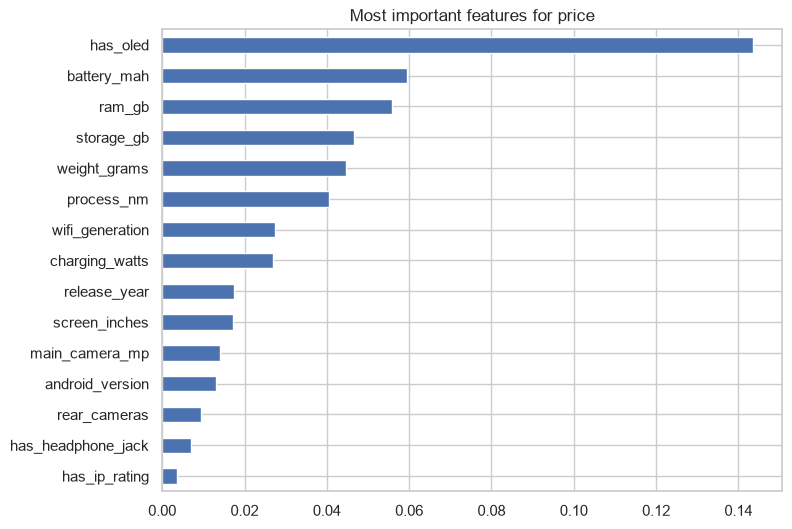

In [21]:
# which features matter most?
test_mask = np.arange(len(y)) % 5 == 0         # simple 20% hold-out
model_for_importance = new_boosting().fit(X[~test_mask], y[~test_mask])
importance = permutation_importance(model_for_importance, X[test_mask], y[test_mask], n_repeats=5, random_state=0)

pd.Series(importance.importances_mean, index=X.columns).sort_values().tail(15).plot.barh(
    figsize=(8, 6), title="Most important features for price")
plt.show()

## 12. Bargain finder
I compare the real price with the price the model expects from the specs.

In [22]:
final_model = new_boosting().fit(X, y)       # final model uses all phones

value = modern.copy()
value["expected_price"] = np.exp(best)
value["value_gap"] = np.log(value["expected_price"] / value["price_inr"])
value["value_gap"] -= value.groupby("price_type")["value_gap"].transform("mean")   # fair between official / unofficial
value["cheaper_than_expected_%"] = (1 - np.exp(-value["value_gap"])) * 100

candidates = value[(value["status"] == "Available") & (value["release_year"] >= 2023)
                   & (value["price_inr"] >= 4000) & (value["days_since_price_update"] <= 365)]
show = ["brand", "model", "price_inr", "price_type", "expected_price", "cheaper_than_expected_%", "ram_gb", "storage_gb"]

print("Cheaper than their specs suggest (possible bargains):")
display(candidates.sort_values("value_gap", ascending=False)[show].head(15).round(0))
print("More costly than their specs suggest:")
display(candidates.sort_values("value_gap")[show].head(15).round(0))

Cheaper than their specs suggest (possible bargains):


,brand,model,price_inr,price_type,expected_price,cheaper_than_expected_%,ram_gb,storage_gb
1880,Motorola,Razr 40,39050.0,unofficial,86816.0,54.0,8.0,256.0
306,Samsung,Galaxy M35 (8GB RAM),16330.0,unofficial,35952.0,53.0,8.0,128.0
1335,Samsung,Galaxy M35,14910.0,unofficial,30747.0,50.0,6.0,128.0
258,Xiaomi,Redmi Turbo 4 Pro,28045.0,unofficial,57789.0,50.0,12.0,256.0
188,ZTE,nubia Z60S Pro (16GB+512GB),41890.0,unofficial,79174.0,46.0,16.0,512.0
234,Samsung,Galaxy M54,15620.0,unofficial,29093.0,45.0,8.0,128.0
745,Samsung,Galaxy Z Fold5 (512GB),92300.0,unofficial,170891.0,44.0,12.0,512.0
443,Xiaomi,Redmi Note 12 5G (8GB RAM),11076.0,unofficial,20249.0,44.0,8.0,256.0
1954,Honor,X8b,21299.0,official,36559.0,44.0,8.0,512.0
1388,Samsung,Galaxy S24 Ultra (512GB),80230.0,unofficial,141868.0,42.0,12.0,512.0


More costly than their specs suggest:


,brand,model,price_inr,price_type,expected_price,cheaper_than_expected_%,ram_gb,storage_gb
450,Huawei,Mate XT Ultimate (1TB),482800.0,unofficial,91287.0,-444.0,16.0,1024.0
452,Huawei,Mate XT Ultimate (512GB),390500.0,unofficial,91287.0,-340.0,16.0,512.0
625,Nokia,XR21 Limited Edition,56800.0,official,18506.0,-198.0,6.0,128.0
842,Huawei,Mate XT Ultimate,305300.0,unofficial,115024.0,-173.0,16.0,256.0
906,HTC,Desire 310 dual sim,10579.0,official,4524.0,-127.0,0.0,4.0
1179,Samsung,Galaxy Z Flip6,113599.0,official,54241.0,-103.0,12.0,256.0
290,Oukitel,WP33 Pro,42600.0,unofficial,21700.0,-102.0,8.0,256.0
378,Samsung,Galaxy S25 Plus,122120.0,official,59276.0,-100.0,12.0,256.0
289,TCL,40 NxtPaper,28400.0,unofficial,14776.0,-98.0,16.0,256.0
2470,Xiaomi,14 Ultra,95850.0,unofficial,51252.0,-92.0,12.0,256.0


## 13. Guess the price of upcoming / rumored phones
These are rough guesses, not real prices.

In [23]:
no_price = smartphones[smartphones["price_inr"].isna() & smartphones["status"].isin(["Upcoming", "Rumored"])
                       & smartphones["ram_gb"].notna() & (smartphones["release_year"].fillna(2025) >= 2024)].copy()
X_no_price = make_features(no_price).reindex(columns=X.columns, fill_value=0)

no_price["expected_price"] = np.exp(final_model.predict(X_no_price))
no_price["likely_lowest"] = no_price["expected_price"] / range_factor
no_price["likely_highest"] = no_price["expected_price"] * range_factor

print("Phones without price:", len(no_price))
no_price.sort_values("expected_price", ascending=False)[
    ["brand", "model", "status", "ram_gb", "storage_gb", "expected_price", "likely_lowest", "likely_highest"]].head(15).round(0)

Phones without price: 351


,brand,model,status,ram_gb,storage_gb,expected_price,likely_lowest,likely_highest
1192,Samsung,Galaxy Z Fold Special,Upcoming,16.0,512.0,192197.0,147760.0,249996.0
746,Huawei,Mate 70 RS Ultimate,Upcoming,16.0,512.0,137546.0,105745.0,178910.0
1239,Apple,iPhone 17 Pro,Rumored,8.0,128.0,130103.0,100023.0,169229.0
1236,Apple,iPhone 17 Pro Max,Rumored,12.0,256.0,118343.0,90982.0,153933.0
708,Tecno,Phantom V Fold2 Pro,Rumored,12.0,512.0,101426.0,77976.0,131928.0
1234,Apple,iPhone 17 Plus,Rumored,8.0,128.0,101281.0,77865.0,131740.0
753,Huawei,Mate X6,Upcoming,12.0,256.0,100322.0,77128.0,130493.0
769,Apple,iPhone 17 Air,Rumored,8.0,128.0,98887.0,76024.0,128626.0
986,Sharp,Aquos R9 pro,Upcoming,12.0,512.0,95626.0,73517.0,124383.0
1244,Apple,iPhone 17,Rumored,8.0,128.0,91923.0,70670.0,119567.0


## 14. Segments (clustering)
KMeans puts similar phones in groups. I sort the groups from simple to advanced phones.

In [24]:
seg = smartphones[(smartphones["release_year"] >= FIRST_YEAR) & smartphones["ram_gb"].notna()
                  & smartphones["battery_mah"].notna()].reset_index(drop=True)

seg_features = make_features(seg).drop(columns=["release_year"])
seg_features["refresh_rate_hz"] = seg_features["refresh_rate_hz"].fillna(60)
for column in ["ram_gb", "storage_gb", "charging_watts", "main_camera_mp"]:
    seg_features[column] = np.log2(seg_features[column].clip(lower=0.25))
seg_features = seg_features.loc[:, seg_features.notna().mean() > 0.5]
seg_scaled = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(seg_features))

seg["group_raw"] = KMeans(6, n_init=20, random_state=0).fit_predict(seg_scaled)

# order the groups by RAM + storage (small to big)
order = seg.groupby("group_raw")[["ram_gb", "storage_gb"]].median().rank().sum(axis=1).sort_values().index
seg["segment"] = seg["group_raw"].map({old: new + 1 for new, old in enumerate(order)})

summary = seg.groupby("segment").agg(
    phones=("model", "size"), median_price=("price_inr", "median"), ram_gb=("ram_gb", "median"),
    storage_gb=("storage_gb", "median"), battery_mah=("battery_mah", "median"),
    share_5g=("has_5g", "mean"), share_oled=("has_oled", "mean"), typical_year=("release_year", "median"))
summary["top_brands"] = seg.groupby("segment")["brand"].agg(
    lambda b: ", ".join(f"{n} {v:.0%}" for n, v in b.value_counts(normalize=True).head(3).items()))

print("Segment 1 = simplest phones ... Segment 6 = most advanced phones")
summary.round(2)

Segment 1 = simplest phones ... Segment 6 = most advanced phones


,phones,median_price,ram_gb,storage_gb,battery_mah,share_5g,share_oled,typical_year,top_brands
segment,,,,,,,,,
1,395,7099.64,3.0,32.0,4000.0,0.01,0.03,2020.0,"Symphony 14%, Walton 12%, Tecno 9%"
2,1,8519.29,3.0,32.0,5000.0,0.00,0.00,2020.0,Samsung 100%
3,280,8164.29,4.0,128.0,5000.0,0.08,0.03,2024.0,"Itel 15%, Realme 12%, ZTE 8%"
4,898,14909.29,6.0,128.0,5000.0,0.27,0.34,2022.0,"Xiaomi 22%, Samsung 14%, Realme 11%"
5,69,115019.29,6.0,256.0,3274.0,0.86,0.90,2022.0,Apple 100%
6,1141,37630.00,12.0,256.0,5000.0,0.95,0.94,2024.0,"Xiaomi 18%, Vivo 15%, Realme 9%"


## 15. Find cheaper alternatives to a phone

In [25]:
priced = seg[seg["price_inr"].notna()].reset_index(drop=True)
priced_scaled = seg_scaled[seg["price_inr"].notna().values]
finder = NearestNeighbors(n_neighbors=40).fit(priced_scaled)


def cheaper_alternatives(name_part, how_many=6):
    # type part of a phone name, for example 'Galaxy A55'
    full_name = priced["brand"] + " " + priced["model"]
    matches = priced.index[full_name.str.contains(name_part, case=False, regex=False)]
    if len(matches) == 0:
        return "No phone found with that name"
    chosen = matches[0]
    _, neighbours = finder.kneighbors(priced_scaled[[chosen]])
    similar = priced.iloc[neighbours[0][1:]]
    similar = similar[(similar["price_inr"] < priced.loc[chosen, "price_inr"]) & (similar["status"] == "Available")]
    print(f"Chosen: {full_name[chosen]} costs Rs {priced.loc[chosen, 'price_inr']:,.0f}")
    return similar[["brand", "model", "price_inr", "ram_gb", "storage_gb", "battery_mah"]].head(how_many).round(0)


cheaper_alternatives("Galaxy A55")

Chosen: Samsung Galaxy A55 5G costs Rs 44,019


,brand,model,price_inr,ram_gb,storage_gb,battery_mah
2055,Samsung,Galaxy A35,33369.0,8.0,128.0,5000.0
1370,Samsung,Galaxy A55 (256GB),31240.0,8.0,256.0,5000.0
1006,Samsung,Galaxy A35 (256GB),24630.0,8.0,256.0,5000.0
1228,Samsung,Galaxy A55 (12GB/256GB),32660.0,12.0,256.0,5000.0
755,Samsung,Galaxy A26,24849.0,8.0,128.0,5000.0
185,Samsung,Galaxy A26 (8GB+256GB),21229.0,8.0,256.0,5000.0


## 16. Price a new phone yourself
Change the numbers and run the cell.

In [26]:
def estimate_price(chipset="Qualcomm", **specs):
    # example: estimate_price(ram_gb=8, storage_gb=256, battery_mah=5000, has_5g=1)
    phone = pd.DataFrame([{c: np.nan for c in X.columns}])
    phone["release_year"] = 2025
    for name, value in specs.items():
        if name not in phone.columns:
            raise ValueError(f"Unknown spec '{name}'. Choose from: {list(X.columns)}")
        phone[name] = float(value)
    for column in [c for c in phone.columns if c.startswith("chipset_")]:
        phone[column] = 0.0
    if f"chipset_{chipset}" in phone.columns:
        phone[f"chipset_{chipset}"] = 1.0
    price = float(np.exp(final_model.predict(phone)[0]))
    return {"expected_price": round(price, -2),
            "likely_lowest": float(round(price / range_factor, -2)),
            "likely_highest": float(round(price * range_factor, -2))}


print("Budget phone   :", estimate_price("Unisoc", ram_gb=4, storage_gb=64, battery_mah=5000, screen_inches=6.6,
                                         refresh_rate_hz=60, charging_watts=10, main_camera_mp=13, has_5g=0))
print("Mid-range phone:", estimate_price("MediaTek", ram_gb=8, storage_gb=256, battery_mah=5000, screen_inches=6.7,
                                         refresh_rate_hz=120, charging_watts=67, main_camera_mp=50, has_5g=1, has_oled=1))
print("Flagship phone :", estimate_price("Qualcomm", ram_gb=12, storage_gb=512, battery_mah=5000, screen_inches=6.8,
                                         refresh_rate_hz=120, charging_watts=80, main_camera_mp=200, has_5g=1, has_oled=1,
                                         has_wireless_charging=1, has_ip_rating=1))

Budget phone   : {'expected_price': 14100.0, 'likely_lowest': 10900.0, 'likely_highest': 18400.0}
Mid-range phone: {'expected_price': 22100.0, 'likely_lowest': 17000.0, 'likely_highest': 28700.0}
Flagship phone : {'expected_price': 38300.0, 'likely_lowest': 29400.0, 'likely_highest': 49800.0}


## 17. Key findings

In [31]:
top5 = brand_counts.head(5).sum() / brand_counts.sum() * 100
first_year, last_year = median_by_year.index.min(), median_by_year.index.max()
good = scores["Gradient boosting"]
careless_score = scores["Gradient boosting - careless split (too optimistic)"]
top_feature = feature_table.iloc[0]

print(f'''
MARKET
- {len(smartphones)} smartphones from {smartphones["brand"].nunique()} brands. The top 5 brands hold {top5:.0f}% of listings.
- Median price is Rs {smartphones["price_inr"].median():,.0f}. The average is Rs {smartphones["price_inr"].mean():,.0f} because a few phones are very costly.
- Unofficial prices are about {(1 - ratio.median()) * 100:.0f}% below official prices for the same phone.

TRENDS ({first_year:.0f} to {last_year:.0f})
- Median RAM: {median_by_year.loc[first_year, "ram_gb"]:.0f} GB -> {median_by_year.loc[last_year, "ram_gb"]:.0f} GB
- Median storage: {median_by_year.loc[first_year, "storage_gb"]:.0f} GB -> {median_by_year.loc[last_year, "storage_gb"]:.0f} GB

WHAT RAISES PRICE
- Biggest extra price for the same specs: "{top_feature["feature"]}" ({top_feature["extra_price_%"]:+.0f}%).
- Doubling RAM changes price by {(np.exp(coef["log2_ram"]) - 1) * 100:+.0f}%, doubling storage by {(np.exp(coef["log2_storage"]) - 1) * 100:+.0f}%.

PREDICTION
- Price can be predicted from specs with R2 = {good["R2"]} and a typical error of {good["typical error %"]}%.
- A careless split would show R2 = {careless_score["R2"]}. That is too optimistic, so I trust the grouped split.

LIMITS
- Prices are in Taka converted with an approximate rate. Rumored and upcoming phone prices are only guesses.
''')


MARKET
- 4111 smartphones from 66 brands. The top 5 brands hold 42% of listings.
- Median price is Rs 14,199. The average is Rs 24,612 because a few phones are very costly.
- Unofficial prices are about 22% below official prices for the same phone.

TRENDS (2019 to 2025)
- Median RAM: 4 GB -> 8 GB
- Median storage: 64 GB -> 256 GB

WHAT RAISES PRICE
- Biggest extra price for the same specs: "Name has 'Ultra'" (+64%).
- Doubling RAM changes price by +67%, doubling storage by +20%.

PREDICTION
- Price can be predicted from specs with R2 = 0.929 and a typical error of 12.3%.
- A careless split would show R2 = 0.944. That is too optimistic, so I trust the grouped split.

LIMITS
- Prices are in Taka converted with an approximate rate. Rumored and upcoming phone prices are only guesses.



## 18. Save the results

In [28]:
phones.to_csv("phones_clean.csv", index=False)
feature_table.to_csv("feature_price_differences.csv", index=False)
value.sort_values("value_gap", ascending=False)[["brand", "model", "price_inr", "expected_price", "value_gap", "status"]].to_csv("bargain_finder.csv", index=False)
summary.to_csv("segment_summary.csv")
no_price[["brand", "model", "status", "expected_price", "likely_lowest", "likely_highest"]].to_csv("price_guesses.csv", index=False)
print("Saved result files")

Saved result files


In [67]:
phones[phones['chipset'] == 'Apple A18'][['model','chipset','colors','price_inr','battery_mah']]

,model,chipset,colors,price_inr,battery_mah
332,iPhone 16e (256GB),Apple A18,"Black, White",67450.00,4005.0
418,iPhone 16e,Apple A18,"Black, White",74549.29,4005.0
866,iPhone 16 Plus (256GB SG),Apple A18,"Black, White, Pink, Teal, Ultramarine",131349.29,4383.0
869,iPhone 16 (256GB SG),Apple A18,"Black, White, Pink, Teal, Ultramarine",122829.29,3240.0
872,iPhone 16 Pro (1TB SG),Apple A18,"Black Titanium, White Titanium, Natural Titani...",227199.29,3274.0
873,iPhone 16 Pro (512GB SG),Apple A18,"Black Titanium, White Titanium, Natural Titani...",177499.29,3274.0
874,iPhone 16 Pro (256GB SG),Apple A18,"Black Titanium, White Titanium, Natural Titani...",147679.29,3274.0
1234,iPhone 17 Plus,Apple A18,"Black, White, Pink, Teal, Ultramarine",NaN,4383.0
1239,iPhone 17 Pro,Apple A18,"Black Titanium, White Titanium, Natural Titani...",NaN,3274.0
1244,iPhone 17,Apple A18,"Black, White, Pink, Teal, Ultramarine",NaN,3240.0


In [65]:
phones.describe().T

,count,mean,std,min,25%,50%,75%,max
release_year,4073.0,2020.141174,3.863709,2005.000000,2017.00,2021.00,2024.000,2025.00
official_price,2502.0,16944.647170,23709.908381,681.600000,6177.00,9939.29,17039.290,227199.29
unofficial_price,1575.0,38076.377676,34064.038207,1835.350000,17040.00,27690.00,47569.645,482800.00
price_inr,3771.0,24460.571307,30000.830527,681.600000,7802.90,14199.29,28400.000,482800.00
days_since_price_update,4142.0,232.775471,119.145447,0.000000,134.25,245.00,331.000,491.00
ram_gb,4100.0,5.720352,4.207978,0.062500,2.00,4.00,8.000,64.00
storage_gb,4130.0,135.813613,150.875035,0.009766,16.00,128.00,256.000,1024.00
battery_mah,4140.0,4192.330193,1707.293067,750.000000,3000.00,4562.50,5000.000,28000.00
screen_inches,4138.0,6.046960,0.970854,1.500000,5.50,6.51,6.700,8.12
refresh_rate_hz,2908.0,95.843535,30.670289,30.000000,60.00,90.00,120.000,240.00
